In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

data = pd.read_csv('dataset_timnas.csv')
print("Total baris awal:", len(data))
print("Kolom:", data.columns.tolist())
data.head()

Total baris awal: 635
Kolom: ['text', 'created_at', 'like_count', 'repost_count', 'reply_count', 'url', 'kata_kunci', 'text_clean']


,text,created_at,like_count,repost_count,reply_count,url,kata_kunci,text_clean
0,@SirSimbolon @laazuardii @xcordeirro ibarat ca...,2026-10-11 15:57:12,0,0,0,https://x.com/sekusipapa/status/21092066733448...,garuda,ibarat capo ultras garuda tahun 98
1,@besibakar @ahlireparasi @MusuhMisuh2 @LambeSa...,2026-10-11 15:50:19,0,0,0,https://x.com/sekologic/status/210920493830814...,garuda,stelah era mbg revitalisasi skolah makin bnyak...
2,The #Garuda #Vishnu statue visible for miles i...,2026-10-11 15:50:11,0,0,0,https://x.com/anirusan/status/2109204906423066851,garuda,the garuda vishnu statue visible for miles in ...
3,"zonauang 💞\r\nsejak '22, 35OO++ testii bio🥰\r\...",2026-10-11 15:48:51,0,0,0,https://x.com/skripsijember/status/21092045703...,garuda,zonauang sejak 22 35oo testii bio publish jurn...
4,@txtruangpodcast samaa casenya kaya alat makan...,2026-10-11 15:44:39,3,0,0,https://x.com/preitzle/status/2109203515814076900,garuda,samaa casenya kaya alat makan amp piring garud...


In [12]:
#kolom teks asli, untuk menhitung kata dn hashtag
text_col = 'text' if 'text' in data.columns else 'full_text'

# kolom likes
like_col = 'like_count' if 'like_count' in data.columns else None

print("Kolom teks:", text_col)
print("Kolom likes:", like_col)
print("Jumlah like_count kosong:", data[like_col].isna().sum())

Kolom teks: text
Kolom likes: like_count
Jumlah like_count kosong: 0


In [13]:
# membuang baris dengan like_count yang kosong atau tidak valid
data = data.dropna(subset=[like_col])
data = data[data[like_col].astype(str).str.strip() != '']
data[like_col] = pd.to_numeric(data[like_col], errors='coerce')
data = data.dropna(subset=[like_col])
data = data.reset_index(drop=True)

print("Total baris setelah filter like_count:", len(data))

# f1 jumlah kata (dari teks asli)
data['jumlah_kata'] = data[text_col].astype(str).str.split().str.len()

# f2 jumlah hashtag (dari teks asli)
data['jumlah_hashtag'] = data[text_col].astype(str).apply(lambda t: len(re.findall(r'#\w+', t)))

data[['jumlah_kata', 'jumlah_hashtag', like_col]].head()

Total baris setelah filter like_count: 635


,jumlah_kata,jumlah_hashtag,like_count
0,9,0,0
1,21,0,0
2,16,4,0
3,43,0,0
4,15,0,3


# **EDA**

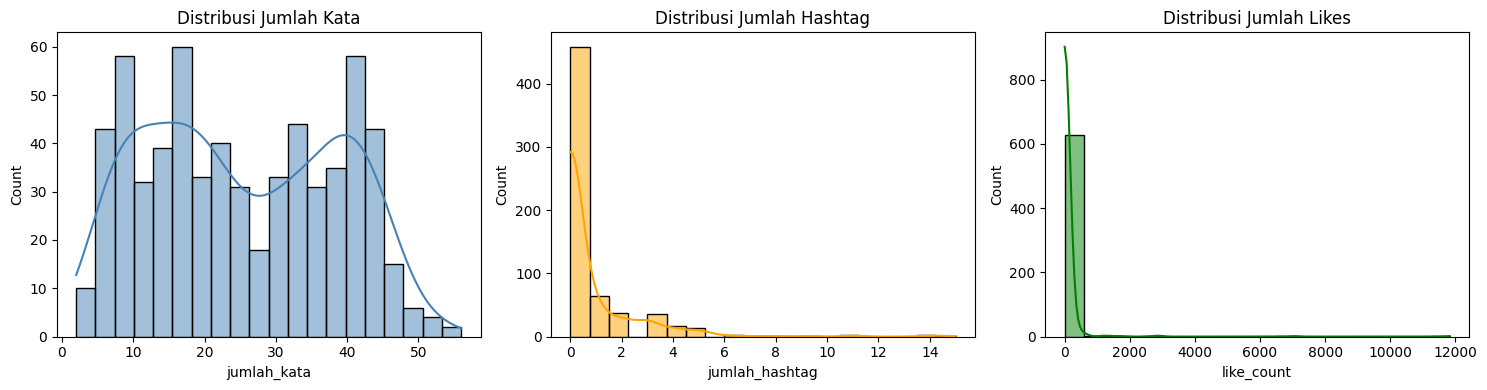

In [14]:
#distribusi data
#lihat sebaran nilai tiap variabel
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(data['jumlah_kata'], bins=20, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribusi Jumlah Kata')

sns.histplot(data['jumlah_hashtag'], bins=20, kde=True, ax=axes[1], color='orange')
axes[1].set_title('Distribusi Jumlah Hashtag')

sns.histplot(data['like_count'], bins=20, kde=True, ax=axes[2], color='green')
axes[2].set_title('Distribusi Jumlah Likes')

plt.tight_layout()
plt.show()

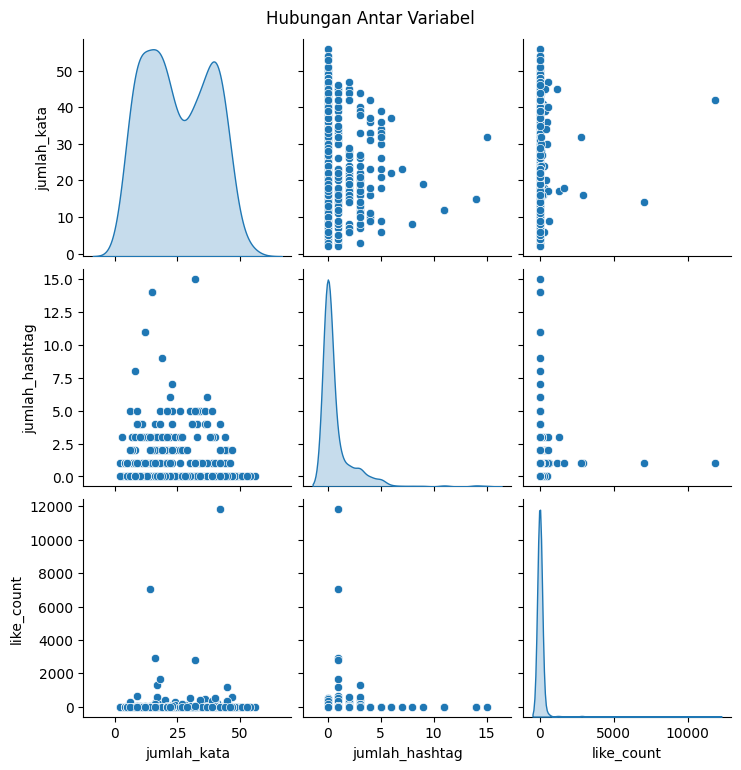

In [15]:
#hub antar variabel
#melihat pola hubungan fitur vs target
sns.pairplot(data[['jumlah_kata', 'jumlah_hashtag', 'like_count']], diag_kind='kde')
plt.suptitle('Hubungan Antar Variabel', y=1.02)
plt.show()

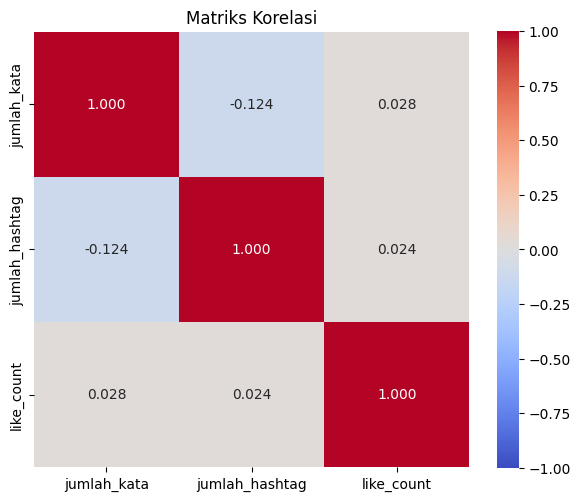

                jumlah_kata  jumlah_hashtag  like_count
jumlah_kata        1.000000       -0.123742    0.027912
jumlah_hashtag    -0.123742        1.000000    0.023853
like_count         0.027912        0.023853    1.000000


In [16]:
#m korelasi, lihat kekuatan dan arah hubungan antar variabel
# Nilai -1 s/d 1:
#   mendekati 1  > korelasi positif kuat
#   mendekati -1 > korelasi negatif kuat
#   mendekati 0  > tidak ada hubungan linear
plt.figure(figsize=(6, 5))
corr = data[['jumlah_kata', 'jumlah_hashtag', 'like_count']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.3f',
            vmin=-1, vmax=1, square=True)
plt.title('Matriks Korelasi')
plt.tight_layout()
plt.show()

print(corr)

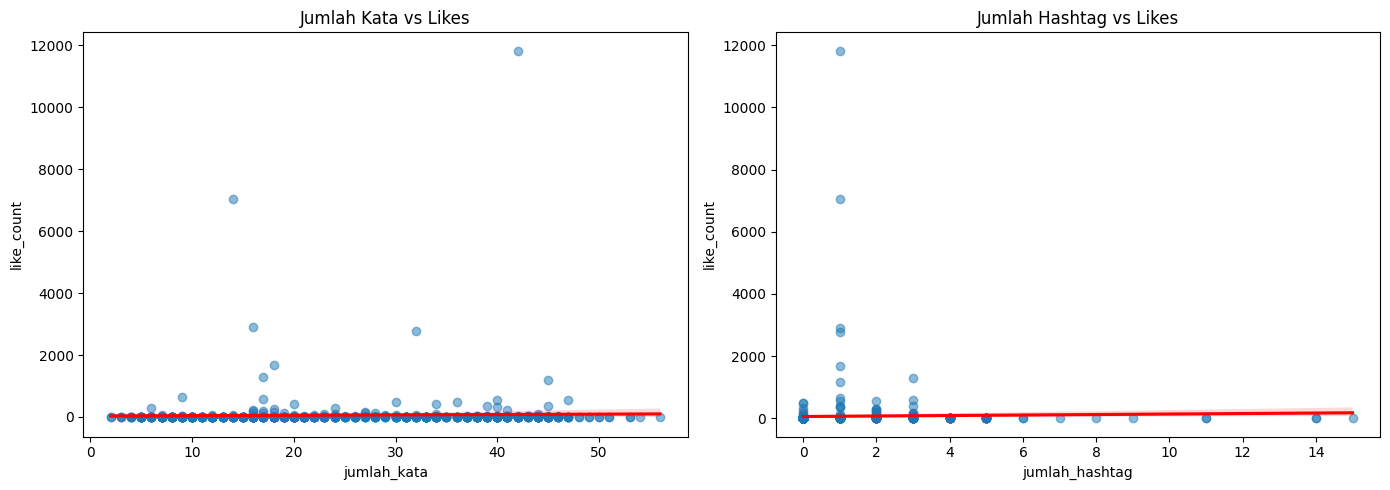

In [17]:
# fitur vs target
# melihat garis tren linear antara fitur dan likes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Jumlah kata vs likes
sns.regplot(data=data, x='jumlah_kata', y='like_count',
            ax=axes[0], scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
axes[0].set_title('Jumlah Kata vs Likes')

# Jumlah hashtag vs likes
sns.regplot(data=data, x='jumlah_hashtag', y='like_count',
            ax=axes[1], scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
axes[1].set_title('Jumlah Hashtag vs Likes')

plt.tight_layout()
plt.show()

In [18]:
X = data[['jumlah_kata', 'jumlah_hashtag']]
y = data[like_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data latih:", len(X_train))
print("Data uji:", len(X_test))

Data latih: 508
Data uji: 127


In [19]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Koefisien jumlah_kata:", model.coef_[0])
print("Koefisien jumlah_hashtag:", model.coef_[1])

Intercept: 21.996980023439498
Koefisien jumlah_kata: 1.5451498446251228
Koefisien jumlah_hashtag: 10.272441005008933


In [20]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"R² : {r2:.4f}")

MAE: 85.60
R² : -0.0787


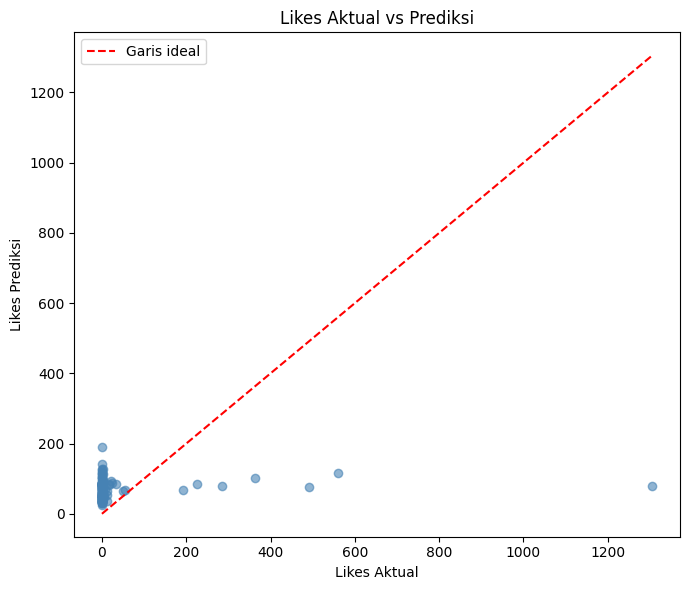

In [21]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='steelblue')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--', label='Garis ideal')
plt.xlabel('Likes Aktual')
plt.ylabel('Likes Prediksi')
plt.title('Likes Aktual vs Prediksi')
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
kata = 20
hashtag = 2

input_data = pd.DataFrame({
    'jumlah_kata': [kata],
    'jumlah_hashtag': [hashtag]
})

pred = model.predict(input_data)[0]
print(f"Estimasi likes untuk {kata} kata & {hashtag} hashtag: {pred:.2f}")

if pred < 0:
    print("⚠️ Hasil negatif → tidak bermakna sebagai jumlah likes (keterbatasan model)")

Estimasi likes untuk 20 kata & 2 hashtag: 73.44
